# Detecting nearby ships from a submarine cable: end-to-end demonstration

**Goal:** decide, from 10 seconds of sound recorded on an underwater cable, whether a vessel is closer than 1000 metres.
Ships can switch off their tracking system (AIS), but the cable can still hear them.

## 1. Setup: tools and settings
Python, **PyTorch** for the neural network, scikit-learn for scaling and metrics, h5py to read the dataset.

In [16]:
import sys, time, importlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import h5py
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay

T0 = time.time()
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.append(str(ROOT / "src"))
import models, training, evaluation
for m in (models, training, evaluation):
    importlib.reload(m)
from models import ANNModel
from training import train_model
from evaluation import predict_model

# ----- settings -----
DATA_PATH = r"C:/Users/urvi_/Downloads/dataset.h5"
RESULTS = ROOT / "results"
FEATURES = RESULTS / "features_all_days_v2.npz"
QUICK = True        
LIVE_DAYS = ["2023-06-22", "2023-06-24", "2023-06-25"]
DEMO_DAY = "2023-06-24"
THRESHOLD_M = 1000
BLUE, AMBER, GREY, INK = "#1B6CA8", "#E8A33D", "#8A99A8", "#12263A"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| device:", device, "|",
      torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU")

PyTorch 2.6.0+cu124 | device: cuda | NVIDIA GeForce RTX 4050 Laptop GPU


## 2. The data
The dataset is public (**Marlinks-NS**, licence CC BY 4.0): 10 days of recordings from a 28 km cable in the North Sea.
Vessel identities are removed and the cable position is displaced for security.
Each **recording** covers 10 seconds and is a grid of 250 channels (positions along the cable) by 100 frequency bands.
Its label comes from ship tracking (AIS): the distance in metres to the nearest vessel.

Datasets in the file: ['X', 'datetimes', 'ship_info', 'y']
Energy values: (74771, 250, 100) = recordings x channels x frequency bands

Recording 4: 2023-06-16 02:00:48+00:00 | nearest vessel 853 m -> label near
Smallest value: 0.0 | largest value: 1.9230966107360398e-11


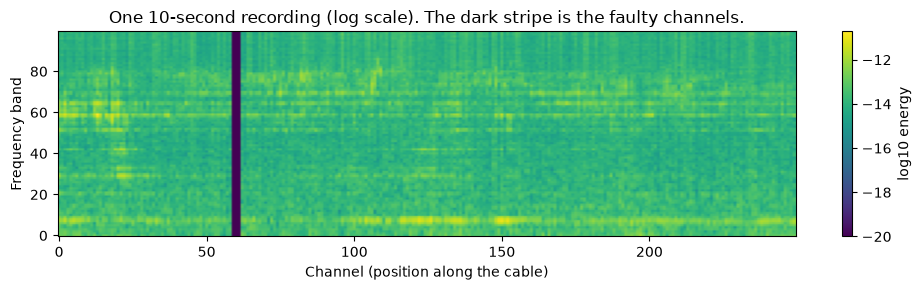

In [17]:
f = h5py.File(DATA_PATH, "r")
print("Datasets in the file:", list(f.keys()))
X_raw = f["X"]
print("Energy values:", X_raw.shape, "= recordings x channels x frequency bands")
dist_all = f["y"][:]
times_all = pd.to_datetime([t.decode() if isinstance(t, bytes) else str(t) for t in f["datetimes"][:]])
ship_len = f["ship_info"]["length"][:].astype(float)

i = 4
rec = X_raw[i]
print(f"\nRecording {i}: {times_all[i]} | nearest vessel {dist_all[i]:.0f} m -> label {'near' if dist_all[i] < THRESHOLD_M else 'far'}")
print("Smallest value:", rec.min(), "| largest value:", rec.max())

fig, ax = plt.subplots(figsize=(10, 3))
im = ax.imshow(np.log10(rec + 1e-20).T, aspect="auto", origin="lower", cmap="viridis")
ax.set_xlabel("Channel (position along the cable)"); ax.set_ylabel("Frequency band")
plt.colorbar(im, label="log10 energy")
plt.title("One 10-second recording (log scale). The dark stripe is the faulty channels.")
plt.tight_layout(); plt.show()

## 3. Cleaning and preprocessing
The dataset authors flag channels 59, 60 and 61 as faulty. Checking it ourselves:

In [18]:
check = X_raw[:500]
print("Largest value in channels 59, 60, 61:", np.abs(check[:, [59, 60, 61], :]).max())
print("Largest value in a normal channel:   ", np.abs(check[:, 100, :]).max())

Largest value in channels 59, 60, 61: 0.0001655559922942682
Largest value in a normal channel:    0.00016286741006319032


Then three steps turn one recording into numbers a neural network can use:
**drop the faulty channels, take the loudest channel for each band (plus the mean and the 90th percentile), then apply log10.**
The raw values span about ten orders of magnitude, and the network could not learn from them until log10 was applied.

raw (250, 100) -> drop faulty channels (247, 100) -> max, mean and 90th percentile across channels (3 x 100) -> log10 (300,)
Before log10 the values span 3.7e-14 to 1.9e-11; after log10 they span -13.4 to -10.7


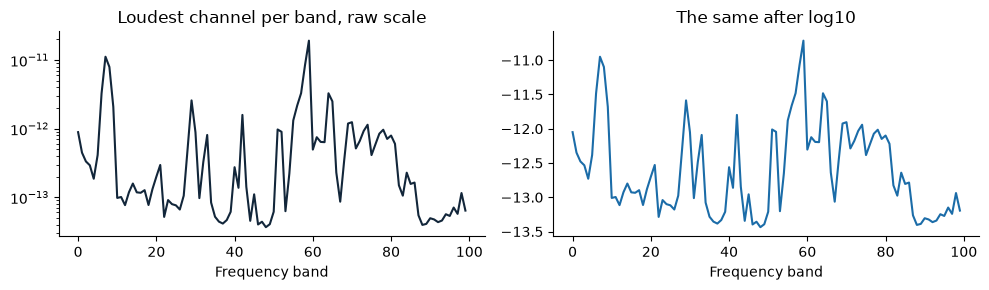

In [19]:
keep = [c for c in range(250) if c not in (59, 60, 61)]
step1 = rec[keep]                                   # drop 3 faulty channels
mx, mean, p90 = step1.max(axis=0), step1.mean(axis=0), np.percentile(step1, 90, axis=0)
features_one = np.log10(np.concatenate([mx, mean, p90]) + 1e-20)

print("raw", rec.shape, "-> drop faulty channels", step1.shape, "-> max, mean and 90th percentile across channels (3 x 100) -> log10", features_one.shape)
print(f"Before log10 the values span {mx.min():.1e} to {mx.max():.1e}; after log10 they span {np.log10(mx + 1e-20).min():.1f} to {np.log10(mx + 1e-20).max():.1f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(mx, color=INK); ax[0].set_yscale("log"); ax[0].set_title("Loudest channel per band, raw scale")
ax[1].plot(np.log10(mx + 1e-20), color=BLUE); ax[1].set_title("The same after log10")
for a in ax:
    a.set_xlabel("Frequency band"); a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## 4. Labels and class balance
A recording is **near (1)** if the nearest vessel is closer than 1000 m, otherwise **far (0)**. 1000 m is the distance cable operators use to start closer tracking.
Only about one recording in three is near, so the loss will give near recordings more weight. The days are also uneven in size.

74,771 recordings | near 24,250 (32.4%) | far 50,521


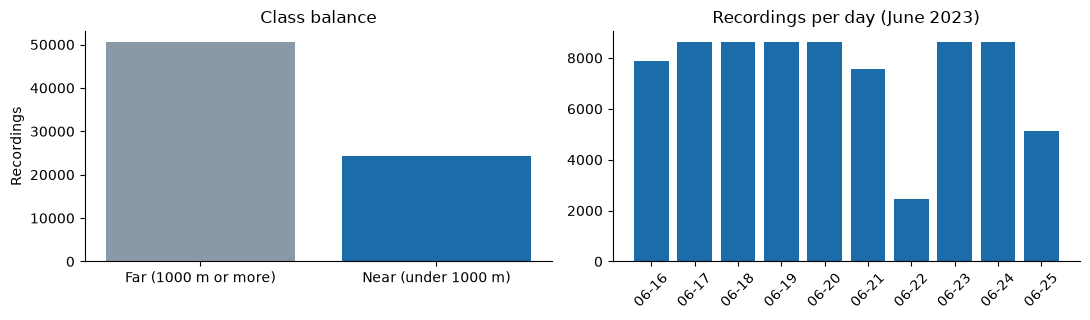

In [20]:
y_all = (dist_all < THRESHOLD_M).astype(int)
day_of = np.array([str(d) for d in times_all.date])
days_sorted = sorted(set(day_of))
print(f"{len(y_all):,} recordings | near {y_all.sum():,} ({y_all.mean():.1%}) | far {(1 - y_all).sum():,}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
ax[0].bar(["Far (1000 m or more)", "Near (under 1000 m)"], [(1 - y_all).sum(), y_all.sum()], color=[GREY, BLUE])
ax[0].set_title("Class balance"); ax[0].set_ylabel("Recordings")
cnt = pd.Series(day_of).value_counts().sort_index()
ax[1].bar([d[-5:] for d in cnt.index], cnt.values, color=BLUE)
ax[1].set_title("Recordings per day (June 2023)"); ax[1].tick_params(axis="x", rotation=45)
for a in ax:
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## 5. Model inputs for all 74,771 recordings
The three steps above are applied to every recording in chunks (done once and saved, because it takes 10 to 15 minutes).

In [21]:
def build_features(path, chunk=500, bad=(59, 60, 61)):
    keep = [c for c in range(250) if c not in bad]
    out = np.empty((len(y_all), 300), dtype=np.float32)
    for s in range(0, len(y_all), chunk):
        block = X_raw[s:s + chunk][:, keep, :]
        parts = [block.max(axis=1), block.mean(axis=1), np.percentile(block, 90, axis=1)]
        out[s:s + chunk] = np.log10(np.concatenate(parts, axis=1) + 1e-20)
    np.savez(path, X=out, y=dist_all, dt=np.array([str(t) for t in times_all]))

if not FEATURES.exists():
    print("Building the feature file from the raw data (about 15 minutes)...")
    build_features(FEATURES)
X = np.load(FEATURES)["X"]
assert X.shape == (len(y_all), 300)
print("Model inputs:", X.shape, "= recordings x features (100 max + 100 mean + 100 90th percentile)")

Model inputs: (74771, 300) = recordings x features (100 max + 100 mean + 100 90th percentile)


## 6. How the model is tested without cheating
Recordings next to each other in time look almost the same, so a random split would leak. Instead the data is split **by day**:
one day is the **test day** (never seen), the next day is the **validation day** (only used to decide when to stop training), and the other eight days are for **training**.
This is repeated so that every day is the test day once. The scaler and the class weight use the training days only.

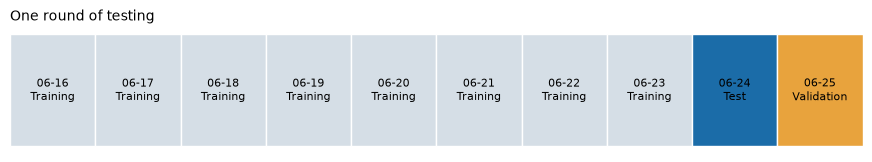

This round: 61,019 training recordings, 5,136 validation, 8,616 test


In [22]:
def split_days(test_day):
    return days_sorted[(days_sorted.index(test_day) + 1) % len(days_sorted)]

val_day = split_days(DEMO_DAY)
fig, ax = plt.subplots(figsize=(11, 1.6))
for k, d in enumerate(days_sorted):
    role = "Test" if d == DEMO_DAY else "Validation" if d == val_day else "Training"
    ax.barh(0, 1, left=k, color={"Test": BLUE, "Validation": AMBER, "Training": "#D5DEE6"}[role], edgecolor="white")
    ax.text(k + 0.5, 0, f"{d[-5:]}\n{role}", ha="center", va="center", fontsize=8)
ax.set_xlim(0, len(days_sorted)); ax.axis("off")
plt.title("One round of testing", loc="left", fontsize=10); plt.show()
n_tr = ((day_of != DEMO_DAY) & (day_of != val_day)).sum()
print(f"This round: {n_tr:,} training recordings, {(day_of == val_day).sum():,} validation, {(day_of == DEMO_DAY).sum():,} test")

## 7. The model
A feedforward neural network (**ANN**) in PyTorch: 300 inputs, two hidden layers (256 and 128 units, ReLU, dropout 0.3 against overfitting), one output.
Loss: binary cross-entropy with a weight of about 2 on near recordings. Optimiser: Adam. Training stops when the validation loss has not improved for 10 epochs, and the best weights are restored.
The original study's neural network was also a simple feedforward network, so this is a fair baseline. A second model, an **LSTM** that reads 5 recordings (50 seconds) in a row, was also tested.

In [23]:
print(ANNModel(input_size=X.shape[1], hidden1=256, hidden2=128, dropout=0.3))

ANNModel(
  (network): Sequential(
    (0): Linear(in_features=300, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=128, out_features=1, bias=True)
  )
)


## 8. Training with a held-out test day (live)

In [24]:
class VesselDetection(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)
    def __len__(self): return len(self.y)
    def __getitem__(self, i): return self.X[i], self.y[i]

def run_fold(test_day, epochs=100, lr=1e-3, batch=64, dropout=0.3, wd=1e-4, seed=42):
    torch.manual_seed(seed); np.random.seed(seed)
    val_day = split_days(test_day)
    test_idx = np.where(day_of == test_day)[0]
    val_idx = np.where(day_of == val_day)[0]
    fit_idx = np.where((day_of != test_day) & (day_of != val_day))[0]

    ss = StandardScaler().fit(X[fit_idx])                       # fitted on the training days only
    def make_loader(idx, shuffle):
        return DataLoader(VesselDetection(ss.transform(X[idx]), y_all[idx]), batch_size=batch, shuffle=shuffle)

    n_far, n_near = (y_all[fit_idx] == 0).sum(), (y_all[fit_idx] == 1).sum()
    criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([n_far / n_near], dtype=torch.float32).to(device))
    model = ANNModel(input_size=X.shape[1], hidden1=256, hidden2=128, dropout=dropout).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    history = train_model(model, make_loader(fit_idx, True), criterion, optimizer, device,
                          epochs=epochs, val_loader=make_loader(val_idx, False), patience=10)

    y_true, y_pred, y_prob = predict_model(model, make_loader(test_idx, False), device)
    y_true, y_pred, y_prob = y_true.astype(int), y_pred.astype(int).flatten(), y_prob.flatten()
    far_f1, near_f1 = f1_score(y_true, y_pred, average=None, zero_division=0)
    metrics = {"test_day": test_day, "best_epoch": int(np.argmin(history["val_loss"])) + 1,
               "accuracy": accuracy_score(y_true, y_pred),
               "weighted_f1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
               "far_f1": far_f1, "near_f1": near_f1, "auc": roc_auc_score(y_true, y_prob)}
    return metrics, history, (y_true, y_pred, y_prob), test_idx

live_days = LIVE_DAYS if QUICK else days_sorted
live, hist, preds, idxs = [], {}, {}, {}
for day in live_days:
    t = time.time()
    r, h, p, ti = run_fold(day)
    live.append(r); hist[day] = h; preds[day] = p; idxs[day] = ti
    print(f">>> {day}: accuracy {r['accuracy']:.3f} | near F1 {r['near_f1']:.3f} | AUC {r['auc']:.3f} | stopped at the best epoch {r['best_epoch']} | {time.time() - t:.0f} s")
live_df = pd.DataFrame(live)

Epoch 1/100 | Train loss: 0.4377 | Val loss: 0.4544
Epoch 2/100 | Train loss: 0.3898 | Val loss: 0.4350
Epoch 3/100 | Train loss: 0.3730 | Val loss: 0.4366
Epoch 4/100 | Train loss: 0.3578 | Val loss: 0.4374
Epoch 5/100 | Train loss: 0.3471 | Val loss: 0.4698
Epoch 6/100 | Train loss: 0.3392 | Val loss: 0.4510
Epoch 7/100 | Train loss: 0.3298 | Val loss: 0.4561
Epoch 8/100 | Train loss: 0.3236 | Val loss: 0.4393
Epoch 9/100 | Train loss: 0.3155 | Val loss: 0.4868
Epoch 10/100 | Train loss: 0.3105 | Val loss: 0.4644
Epoch 11/100 | Train loss: 0.3030 | Val loss: 0.4792
Epoch 12/100 | Train loss: 0.2968 | Val loss: 0.4737
Early stopping at epoch 12
>>> 2023-06-22: accuracy 0.750 | near F1 0.748 | AUC 0.930 | stopped at the best epoch 2 | 62 s
Epoch 1/100 | Train loss: 0.4522 | Val loss: 0.2821
Epoch 2/100 | Train loss: 0.4033 | Val loss: 0.2579
Epoch 3/100 | Train loss: 0.3863 | Val loss: 0.2521
Epoch 4/100 | Train loss: 0.3760 | Val loss: 0.2663
Epoch 5/100 | Train loss: 0.3610 | Val los

## 9. Is it overfitting?
Training loss keeps falling, but validation loss (an unseen day) stops improving after a few epochs. Early stopping picks the weights from the best epoch, so the model is not memorising the training days.

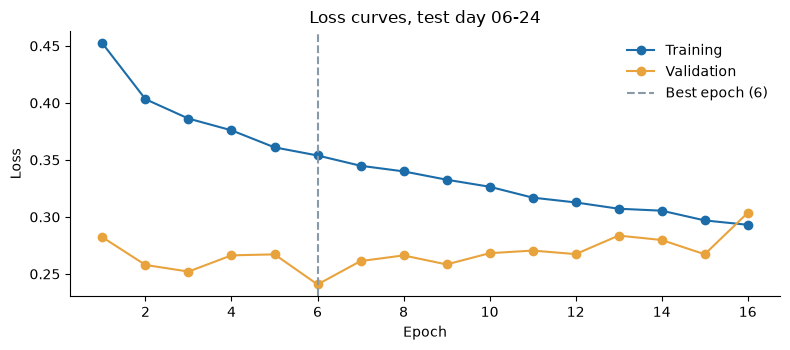

In [25]:
day = DEMO_DAY if DEMO_DAY in hist else live_days[0]
h = hist[day]; n = len(h["train_loss"]); best = int(np.argmin(h["val_loss"])) + 1
plt.figure(figsize=(8, 3.6))
plt.plot(range(1, n + 1), h["train_loss"], marker="o", color=BLUE, label="Training")
plt.plot(range(1, n + 1), h["val_loss"], marker="o", color=AMBER, label="Validation")
plt.axvline(best, ls="--", color=GREY, label=f"Best epoch ({best})")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title(f"Loss curves, test day {day[-5:]}")
plt.legend(frameon=False); plt.gca().spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## 10. Results on the held-out days
- **Accuracy:** share of recordings classified correctly.
- **Near F1:** balance of false alarms and missed ships for the near class, the one that matters. Closer to 1 is better.
- **AUC:** how well the model ranks near recordings above far ones, whatever the threshold. 0.5 is guessing, 1.0 is perfect.

In [26]:
cols = ["accuracy", "weighted_f1", "far_f1", "near_f1", "auc"]
show = live_df[["test_day"] + cols].copy()
show.loc[len(show)] = ["mean"] + live_df[cols].mean().tolist()
print(show.round(3).to_string(index=False))

  test_day  accuracy  weighted_f1  far_f1  near_f1   auc
2023-06-22     0.750        0.750   0.752    0.748 0.930
2023-06-24     0.880        0.881   0.905    0.838 0.951
2023-06-25     0.938        0.938   0.959    0.868 0.977
      mean     0.856        0.857   0.872    0.818 0.953


### What the model says on the test day
Top: the real distance from ship tracking. Bottom: the model's probability from the cable sound alone. The shaded band marks when a vessel really was within 1000 m.

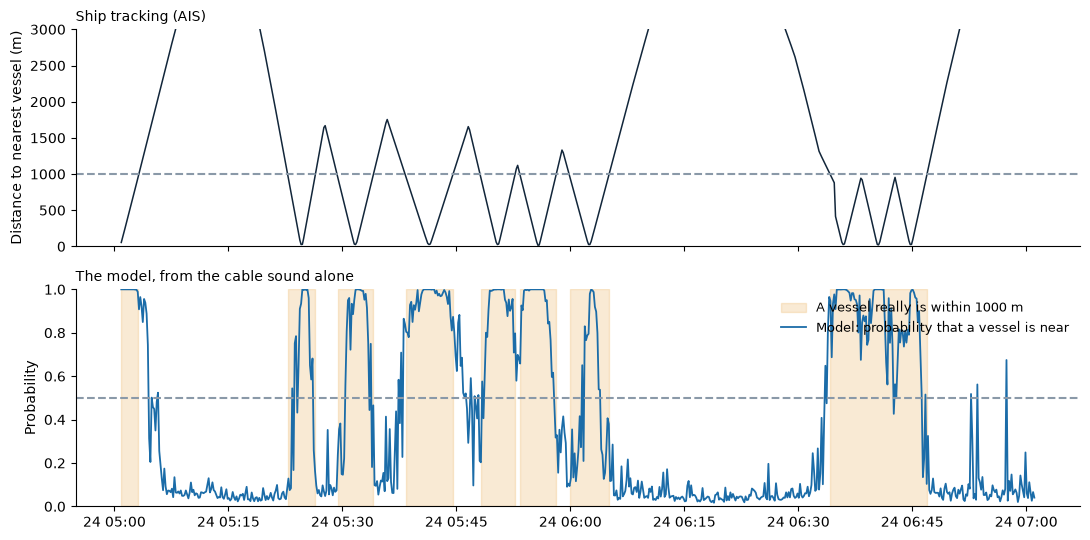

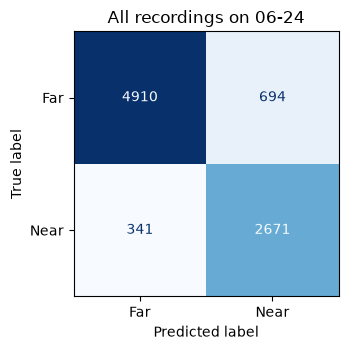

In [27]:
day = DEMO_DAY if DEMO_DAY in preds else live_days[0]
yt, yp, pr = preds[day]
dd = dist_all[idxs[day]]
tt = times_all[idxs[day]]
sl = slice(1800, 1800 + 720)                      # a 2-hour window

fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
a1.plot(tt[sl], dd[sl], color=INK, lw=1.1); a1.axhline(THRESHOLD_M, ls="--", color=GREY)
a1.set_ylim(0, 3000); a1.set_ylabel("Distance to nearest vessel (m)"); a1.set_title("Ship tracking (AIS)", loc="left", fontsize=10)
a2.fill_between(tt[sl], 0, 1, where=yt[sl] == 1, color=AMBER, alpha=0.22, label="A vessel really is within 1000 m")
a2.plot(tt[sl], pr[sl], color=BLUE, lw=1.3, label="Model: probability that a vessel is near")
a2.axhline(0.5, ls="--", color=GREY); a2.set_ylim(0, 1); a2.set_ylabel("Probability")
a2.set_title("The model, from the cable sound alone", loc="left", fontsize=10); a2.legend(loc="upper right", frameon=False, fontsize=9)
for a in (a1, a2):
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(4.2, 3.6))
ConfusionMatrixDisplay(confusion_matrix(yt, yp), display_labels=["Far", "Near"]).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_title(f"All recordings on {day[-5:]}"); plt.tight_layout(); plt.show()

## 10b. Hyperparameter tuning
One setting is changed at a time from the baseline: more dropout, more weight decay, a lower learning rate.
Each is trained on the same three test days. The setting is **chosen by validation loss** (an unseen day, lower is better), so the test days are not used to pick it. Test scores are shown only to see the effect.
Tuning takes about 35 minutes, so it is run once (`RUN_TUNING = True`) and the saved table is loaded after that.

done: baseline
done: dropout 0.5
done: weight decay 1e-3
done: learning rate 3e-4
           setting  validation loss  accuracy  near F1    AUC
          baseline           0.3697    0.8559   0.8180 0.9526
       dropout 0.5           0.3731    0.8597   0.8208 0.9516
 weight decay 1e-3           0.3762    0.8720   0.8284 0.9501
learning rate 3e-4           0.3693    0.8550   0.8173 0.9514


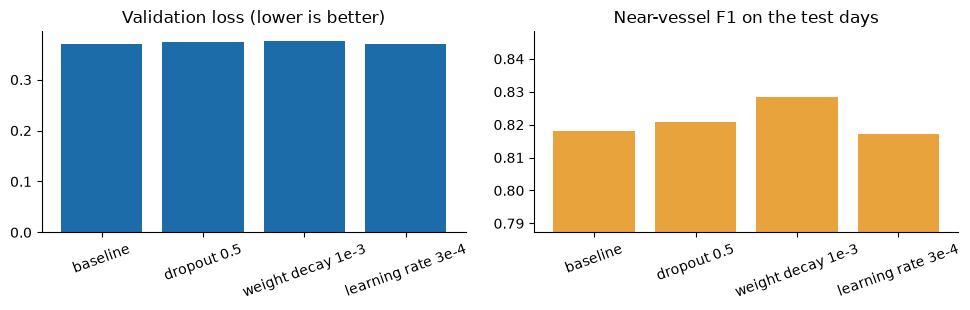

In [28]:
import contextlib, io
RUN_TUNING = True            
TUNE_FILE = RESULTS / "tuning_ann.csv"
configs = {
    "baseline": dict(),
    "dropout 0.5": dict(dropout=0.5),
    "weight decay 1e-3": dict(wd=1e-3),
    "learning rate 3e-4": dict(lr=3e-4),
}
if RUN_TUNING:
    rows = []
    for name, cfg in configs.items():
        res = []
        for day in LIVE_DAYS:
            with contextlib.redirect_stdout(io.StringIO()):          
                r, h, p, ti = run_fold(day, **cfg)
            res.append({**r, "best_val_loss": min(h["val_loss"])})
        d = pd.DataFrame(res)
        rows.append({"setting": name, "validation loss": d["best_val_loss"].mean(), "accuracy": d["accuracy"].mean(),
                     "near F1": d["near_f1"].mean(), "AUC": d["auc"].mean()})
        print("done:", name)
    pd.DataFrame(rows).to_csv(TUNE_FILE, index=False)

if TUNE_FILE.exists():
    tune = pd.read_csv(TUNE_FILE)
    print(tune.round(4).to_string(index=False))
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
    ax[0].bar(tune["setting"], tune["validation loss"], color=BLUE); ax[0].set_title("Validation loss (lower is better)")
    ax[1].bar(tune["setting"], tune["near F1"], color=AMBER); ax[1].set_title("Near-vessel F1 on the test days")
    ax[1].set_ylim(tune["near F1"].min() - 0.03, tune["near F1"].max() + 0.02)
    for a in ax:
        a.tick_params(axis="x", rotation=20); a.spines[["top", "right"]].set_visible(False)
    plt.tight_layout(); plt.show()
else:
    print("No saved tuning table yet. Set RUN_TUNING = True and run this cell once.")

## 11. All ten test days, three models (from the earlier full runs)
The full 10-day runs take about 26 minutes each, so these numbers are loaded from the files saved earlier.
The ANN with 300 features is the model trained above. The LSTM looks at 5 recordings in a row and did not beat the ANN.

             Model  Accuracy  Near F1   AUC  Near F1 spread (std)
 ANN, 100 features     0.876    0.818 0.938                 0.026
 ANN, 300 features     0.877    0.825 0.941                 0.034
LSTM, 5 recordings     0.869    0.814 0.938                 0.039


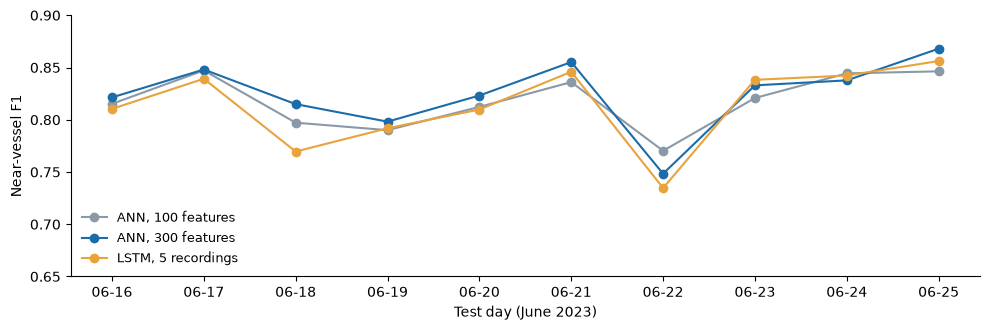

In [29]:
def read_table(name):
    for folder in (RESULTS, RESULTS / "tables"):
        if (folder / name).exists():
            return pd.read_csv(folder / name)
    return None

sources = {"ANN, 100 features": "ann_10day_results.csv", "ANN, 300 features": "ann_v2_10day_results.csv", "LSTM, 5 recordings": "lstm_10day_partial.csv"}
rows, frames = [], {}
for label, fname in sources.items():
    d = read_table(fname)
    if d is None:
        print("Not found:", fname); continue
    frames[label] = d
    rows.append({"Model": label, "Accuracy": d["accuracy"].mean(), "Near F1": d["near_f1"].mean(), "AUC": d["auc"].mean(), "Near F1 spread (std)": d["near_f1"].std()})
print(pd.DataFrame(rows).round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 3.4))
for (label, d), c in zip(frames.items(), [GREY, BLUE, AMBER]):
    ax.plot(d["test_day"].astype(str).str[-5:], d["near_f1"], marker="o", color=c, label=label)
ax.set_ylabel("Near-vessel F1"); ax.set_xlabel("Test day (June 2023)"); ax.set_ylim(0.65, 0.9)
ax.legend(frameon=False, fontsize=9); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## 12. Where the model fails
Detection depends strongly on vessel length. Small vessels are quieter, so they are harder to hear.
(Length is also mixed up with vessel type, so this shows a pattern, not a proven cause.)

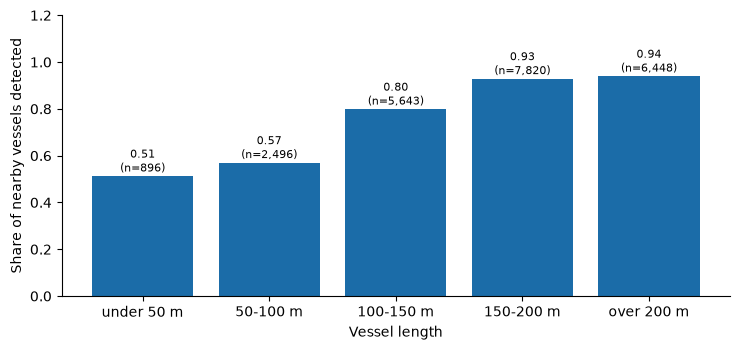

In [30]:
pp = None
for folder in (RESULTS, RESULTS / "tables"):
    if (folder / "ann_v2_10day_predictions.csv").exists():
        pp = pd.read_csv(folder / "ann_v2_10day_predictions.csv"); break

if pp is None:
    print("ann_v2_10day_predictions.csv not found")
else:
    order = np.concatenate([np.where(day_of == d)[0] for d in days_sorted])
    pp["length"] = ship_len[order]
    near = pp[pp["true"] == 1].copy()
    near["size"] = pd.cut(near["length"], [0, 50, 100, 150, 200, 1000], labels=["under 50 m", "50-100 m", "100-150 m", "150-200 m", "over 200 m"])
    s = near.groupby("size", observed=True).agg(n=("true", "size"), recall=("pred", "mean"))
    plt.figure(figsize=(7.5, 3.6))
    plt.bar(s.index.astype(str), s["recall"], color=BLUE)
    for k, (r, n_) in enumerate(zip(s["recall"], s["n"])):
        plt.text(k, r + 0.02, f"{r:.2f}\n(n={n_:,})", ha="center", fontsize=8)
    plt.ylim(0, 1.2); plt.ylabel("Share of nearby vessels detected"); plt.xlabel("Vessel length")
    plt.gca().spines[["top", "right"]].set_visible(False); plt.tight_layout(); plt.show()

## 13. Summary
- **Result:** the ANN detects nearby ships on days it has never seen with about 0.88 accuracy, 0.82 near F1 and 0.94 AUC (mean of 10 test days). That is about the level of the original study's neural network.
- **What worked:** log10 preprocessing (the first model learned nothing without it), class weighting, early stopping, testing by day, and adding mean and 90th-percentile channel features (a small gain).
- **What did not:** the LSTM on 50 seconds of context did not beat the ANN, and averaging predictions over time gave almost nothing.
- **Limits:** small vessels are detected about half the time, and the distance labels come from interpolated ship tracking, so labels near 1000 m are uncertain.
- **Next:** weight small vessels, tune further, and test on another cable.

In [31]:
print(f"Total notebook time: {(time.time() - T0) / 60:.1f} minutes")

Total notebook time: 38.1 minutes
